### Feature Engineering 1

In [1]:
from util.data_aquisition import generate
from util.data_frame import get_data_frame
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2015-2016
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019


In [3]:
df = get_data_frame(data)
df.head()

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,Period_Time,Team_Attack,Power_Game,Empty_Net,Shooters_scorer,Goalies,X_Coordinate,Y_Coordinate
0,2015020364,R,5,Nashville Predators,left,Arizona Coyotes,Shot,Wrist Shot,2015-12-02T01:09:09Z,1,00:36,Nashville Predators,NaN,NaN,Filip Forsberg,Mike Smith,50.0,20.0
1,2015020364,R,12,Nashville Predators,left,Arizona Coyotes,Shot,Wrist Shot,2015-12-02T01:11:09Z,1,01:48,Nashville Predators,NaN,NaN,Cody Hodgson,Mike Smith,77.0,6.0
2,2015020364,R,13,Nashville Predators,left,Arizona Coyotes,Shot,Wrist Shot,2015-12-02T01:11:16Z,1,01:55,Nashville Predators,NaN,NaN,Craig Smith,Mike Smith,86.0,-12.0
3,2015020364,R,18,Nashville Predators,left,Arizona Coyotes,Shot,Backhand,2015-12-02T01:13:00Z,1,03:13,Nashville Predators,NaN,NaN,Viktor Arvidsson,Mike Smith,82.0,7.0
4,2015020364,R,32,Nashville Predators,left,Arizona Coyotes,Shot,Wrist Shot,2015-12-02T01:16:23Z,1,05:09,Nashville Predators,NaN,NaN,Seth Jones,Mike Smith,48.0,-10.0


#### Adding new features

def transform_X(row):
    '''
    Given a row of the original data frame, this function transforms the coordinate X depending on the position of
    the teams in the rink. Since at the end the data is presented in a half-rink (we arbitrarily choose that
    this is the right half of the rink), when the attacking team plays on the right side of the rink , i.e
    the opponent's goal is on the left side, we need to flip the x coordinate.
    '''
    if str(row['Home_Rink']) == 'nan': #In case the rinkside information is not available, we assume the shot
        #is taken from the side that is the closest to the opponent's goal.
        return np.absolute(row['X_Coordinate'])

    else: #Otherwise we use rinkside information to determine whether to flip X coordinate as described above.
        if row['Home_Team'] == row['Team_Attack']:
            if row['Home_Rink'] == 'right':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']
        else:
            if row['Home_Rink'] == 'left':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']

In [5]:
df['X_Transformed'] = df.apply(transform_X, axis=1)
df = df.assign(Distance_From_Net = lambda x : np.sqrt(pow(x["X_Transformed"] - 89, 2) + pow(x["Y_Coordinate"], 2)))
df = df.assign(Angle = lambda x : np.arctan((x["Y_Coordinate"]/(89-x["X_Transformed"])))*180/math.pi)
df["Is_Goal"] = df.Event_Type.apply(lambda x : 1 if x=="Goal" else 0)
df["Empty_Net_Bool"] = df.Empty_Net.apply(lambda x : 1 if x==True else 0)

#### Histograms

In [29]:
sns.set_theme()
sns.set(rc={'figure.figsize':(16,12)})

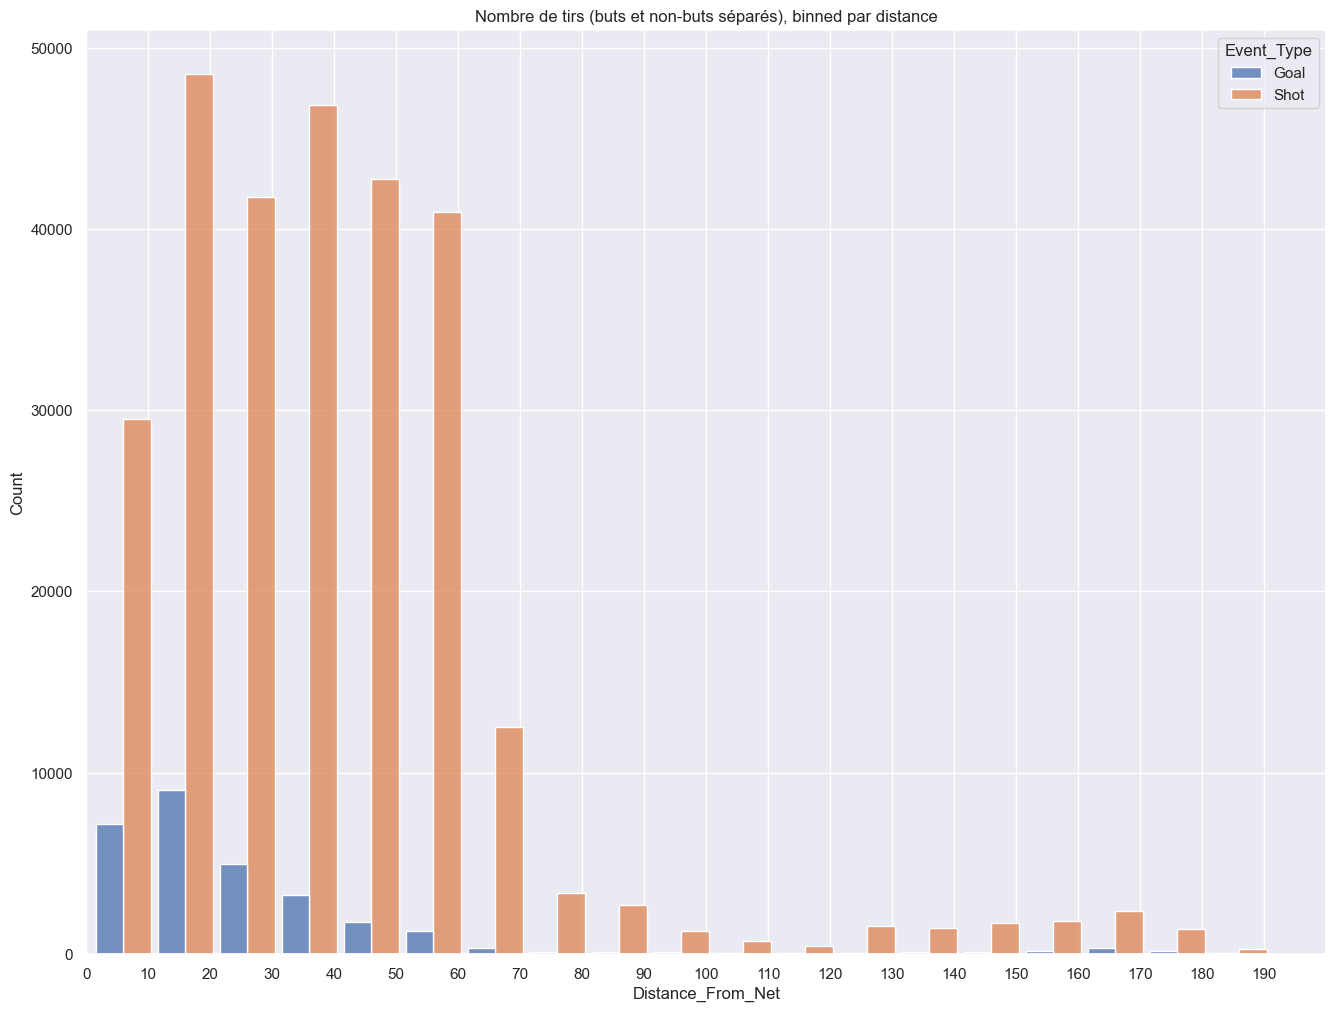

In [34]:
#histogramme du nombre de tirs (buts et non-buts séparés), regroupées (binned) par distance
g = sns.histplot(df, x="Distance_From_Net", hue="Event_Type", multiple="dodge", hue_order=['Goal', 'Shot'], shrink=.9, binwidth=10)
g.set_xlim(0, 200)
g.set_xticks(range(0, 200,10))
plt.title("Nombre de tirs (buts et non-buts séparés), binned par distance")
plt.show(g)

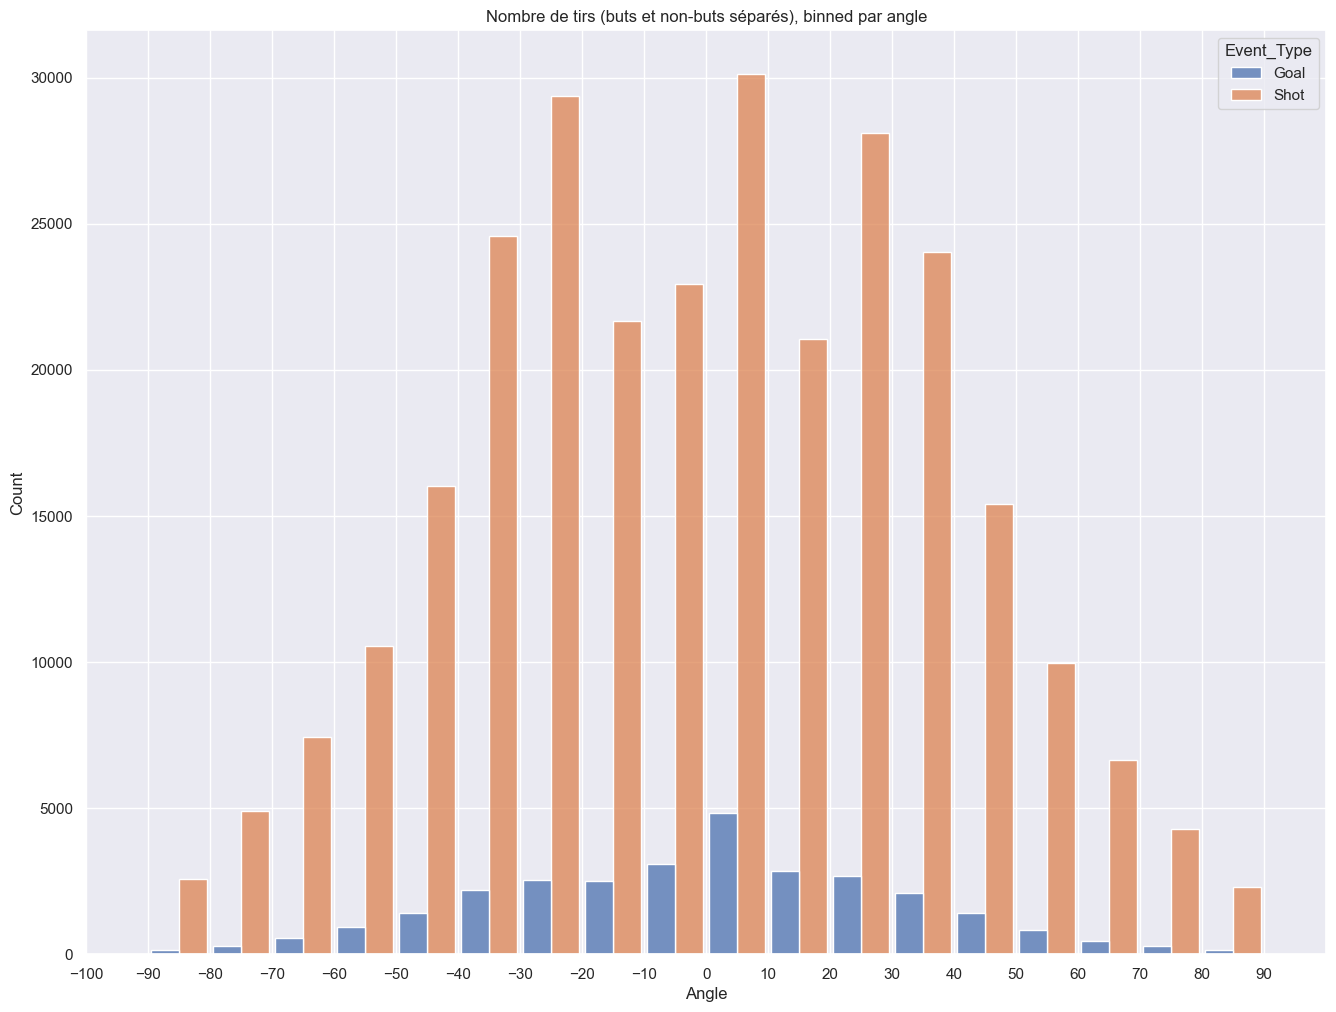

In [45]:
#Un histogramme de nombre de tirs (buts et non-buts séparés), binned par angle
g = sns.histplot(df, x="Angle", hue="Event_Type", multiple="dodge", shrink=.9, hue_order=['Goal', 'Shot'], binwidth=10)
g.set_xlim(-100, 100)
g.set_xticks(range(-100, 100,10))
plt.title("Nombre de tirs (buts et non-buts séparés), binned par angle")
plt.show(g)

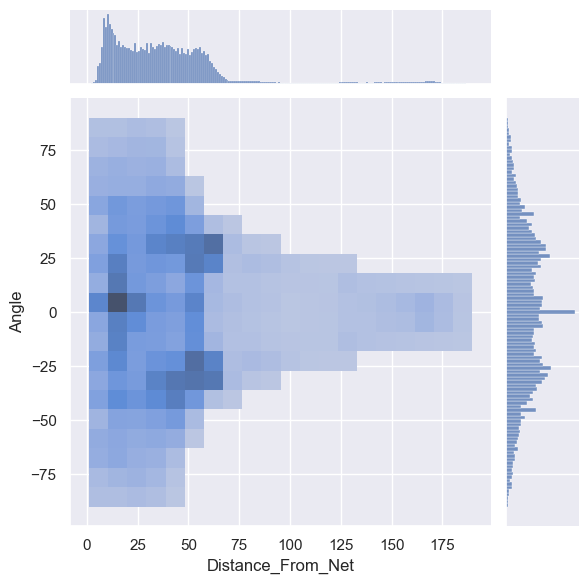

In [35]:
sns.jointplot(data=df, x="Distance_From_Net", y="Angle", kind="hist", bins=20)

#### Goal rate plots

In [36]:
#This function takes a series of event_types (possible types: Shot or Goal) and returns the rate of Goals.
def calculate_rate(event_types):
    Number_of_goals = event_types.value_counts()["Goal"]
    Number_of_shoot = event_types.value_counts()["Shot"]

    #buts / (#pas_de_buts + #buts)
    return Number_of_goals / (Number_of_goals + Number_of_shoot)

In [37]:
WIDTH = 10 #Bin width, can be changed depending on final output

In [38]:
#Creating the 'Distance_bin' representing the bin corresponding to the distance of the shot
df['Distance_bin']=df.Distance_From_Net.map(lambda x: int(np.floor(x/WIDTH)*WIDTH) if not math.isnan(x) else np.nan)

In [39]:
#Creating the 'Angle_bin' representing the bin corresponding to the angle of the shot
df['Angle_bin']=df.Angle.map(lambda x: int(np.floor(x/WIDTH)*WIDTH) if not math.isnan(x) else np.nan)

In [40]:
df = df.dropna(subset='Distance_bin') #We don't want NaNs

In [41]:
df = df.dropna(subset='Angle_bin') #We don't want NaNs

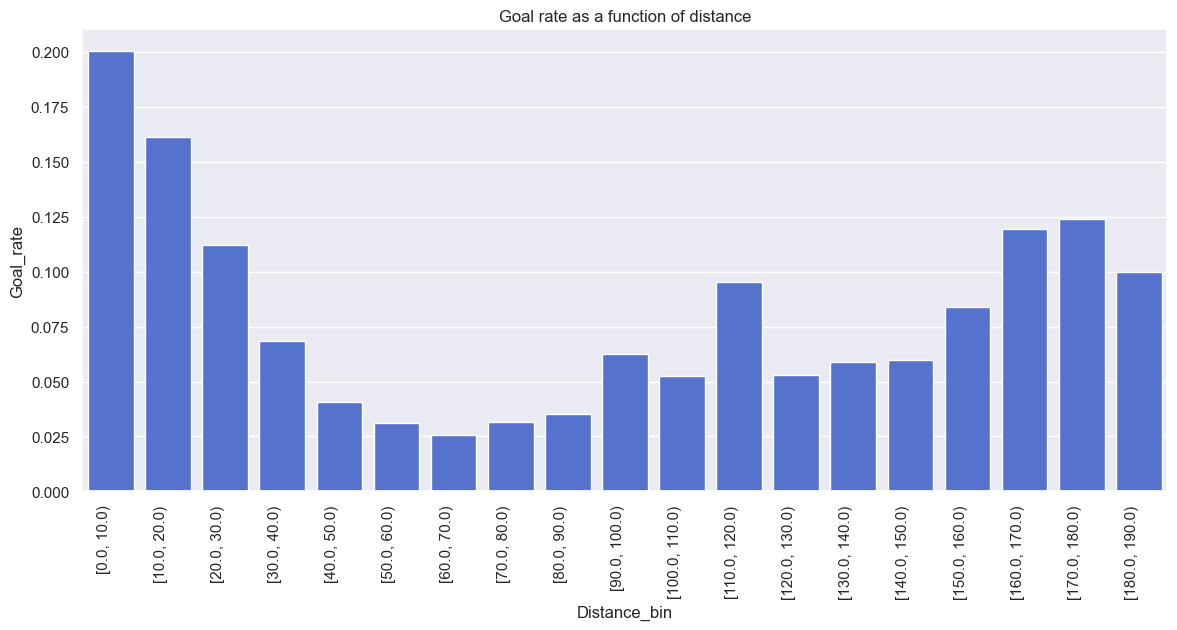

In [42]:
#Grouping by distance bin and calculating the aggregate function: Rate of goals among the group
groups = df.groupby(by='Distance_bin').agg(goal_rate=pd.NamedAgg(column="Event_Type", aggfunc= calculate_rate))
groups = pd.DataFrame({'Distance_bin': groups.index, 'Goal_rate': groups.goal_rate})
plt.figure(figsize=(14,6))
g = sns.barplot(groups, x='Distance_bin', y='Goal_rate', color='royalblue')
g.set_xticklabels([f"[{float(i.get_text())}, {float(i.get_text())+WIDTH})" for i in g.get_xticklabels()], rotation = 90, ha="right")
plt.title(f"Goal rate as a function of distance")
plt.show()

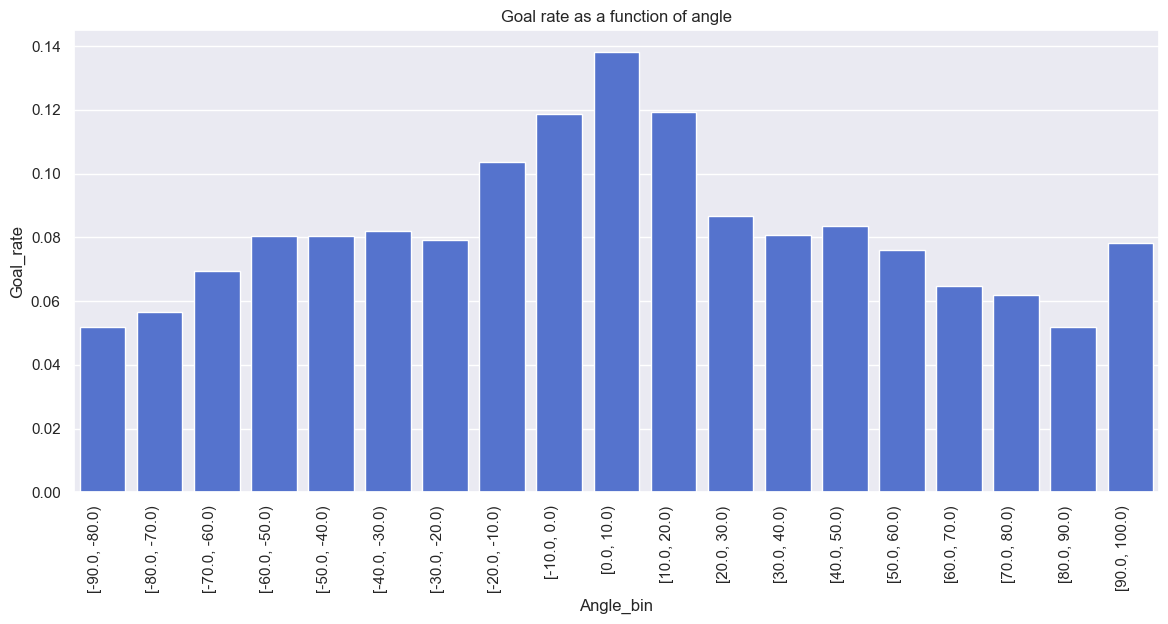

In [48]:
#Grouping by distance bin and calculating the aggregate function: Rate of goals among the group
groups = df.groupby(by='Angle_bin').agg(goal_rate=pd.NamedAgg(column="Event_Type", aggfunc= calculate_rate))
groups = pd.DataFrame({'Angle_bin': groups.index, 'Goal_rate': groups.goal_rate})
plt.figure(figsize=(14,6))
g = sns.barplot(groups, x='Angle_bin', y='Goal_rate', color='royalblue')
g.set_xticklabels([f"[{float(i.get_text())}, {float(i.get_text())+WIDTH})" for i in g.get_xticklabels()], rotation = 90, ha="right")
plt.title(f"Goal rate as a function of angle")

plt.show()

#### Goal only Histogram

In [49]:
df_goals = df[df.Event_Type=="Goal"]
df_goals

,Game_ID,Game_Type,Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Shoot_Type,Time,Period,...,Goalies,X_Coordinate,Y_Coordinate,X_Transformed,Distance_From_Net,Angle,Is_Goal,Empty_Net_Bool,Distance_bin,Angle_bin
13,2015020364,R,87,Nashville Predators,left,Arizona Coyotes,Goal,Wrist Shot,2015-12-02T01:40:51Z,1,...,Pekka Rinne,-45.0,10.0,45.0,45.122057,12.804266,1,0,40,10
31,2015020364,R,158,Nashville Predators,right,Arizona Coyotes,Goal,Tip-In,2015-12-02T02:24:42Z,2,...,Mike Smith,-79.0,-1.0,79.0,10.049876,-5.710593,1,0,10,-10
34,2015020364,R,169,Nashville Predators,right,Arizona Coyotes,Goal,Wrist Shot,2015-12-02T02:33:14Z,2,...,Pekka Rinne,87.0,-7.0,87.0,7.280110,-74.054604,1,0,0,-80
39,2015020364,R,197,Nashville Predators,left,Arizona Coyotes,Goal,Wrist Shot,2015-12-02T02:59:51Z,3,...,Mike Smith,75.0,-2.0,75.0,14.142136,-8.130102,1,0,10,-10
43,2015020364,R,212,Nashville Predators,left,Arizona Coyotes,Goal,Wrist Shot,2015-12-02T03:03:46Z,3,...,Mike Smith,60.0,-7.0,60.0,29.832868,-13.570434,1,0,20,-20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311048,2018021002,R,54,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Wrist Shot,2019-03-03T00:36:07Z,1,...,Frederik Andersen,49.0,-12.0,49.0,41.761226,-16.699244,1,0,40,-20
311061,2018021002,R,104,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Wrist Shot,2019-03-03T00:55:29Z,1,...,Linus Ullmark,-40.0,-7.0,40.0,49.497475,-8.130102,1,0,40,-10
311074,2018021002,R,173,Toronto Maple Leafs,left,Buffalo Sabres,Goal,Snap Shot,2019-03-03T01:40:26Z,2,...,Linus Ullmark,70.0,8.0,70.0,20.615528,22.833654,1,0,20,20
311076,2018021002,R,196,Toronto Maple Leafs,left,Buffalo Sabres,Goal,Deflected,2019-03-03T01:46:40Z,2,...,Linus Ullmark,39.0,-14.0,39.0,51.923020,-15.642246,1,0,50,-20


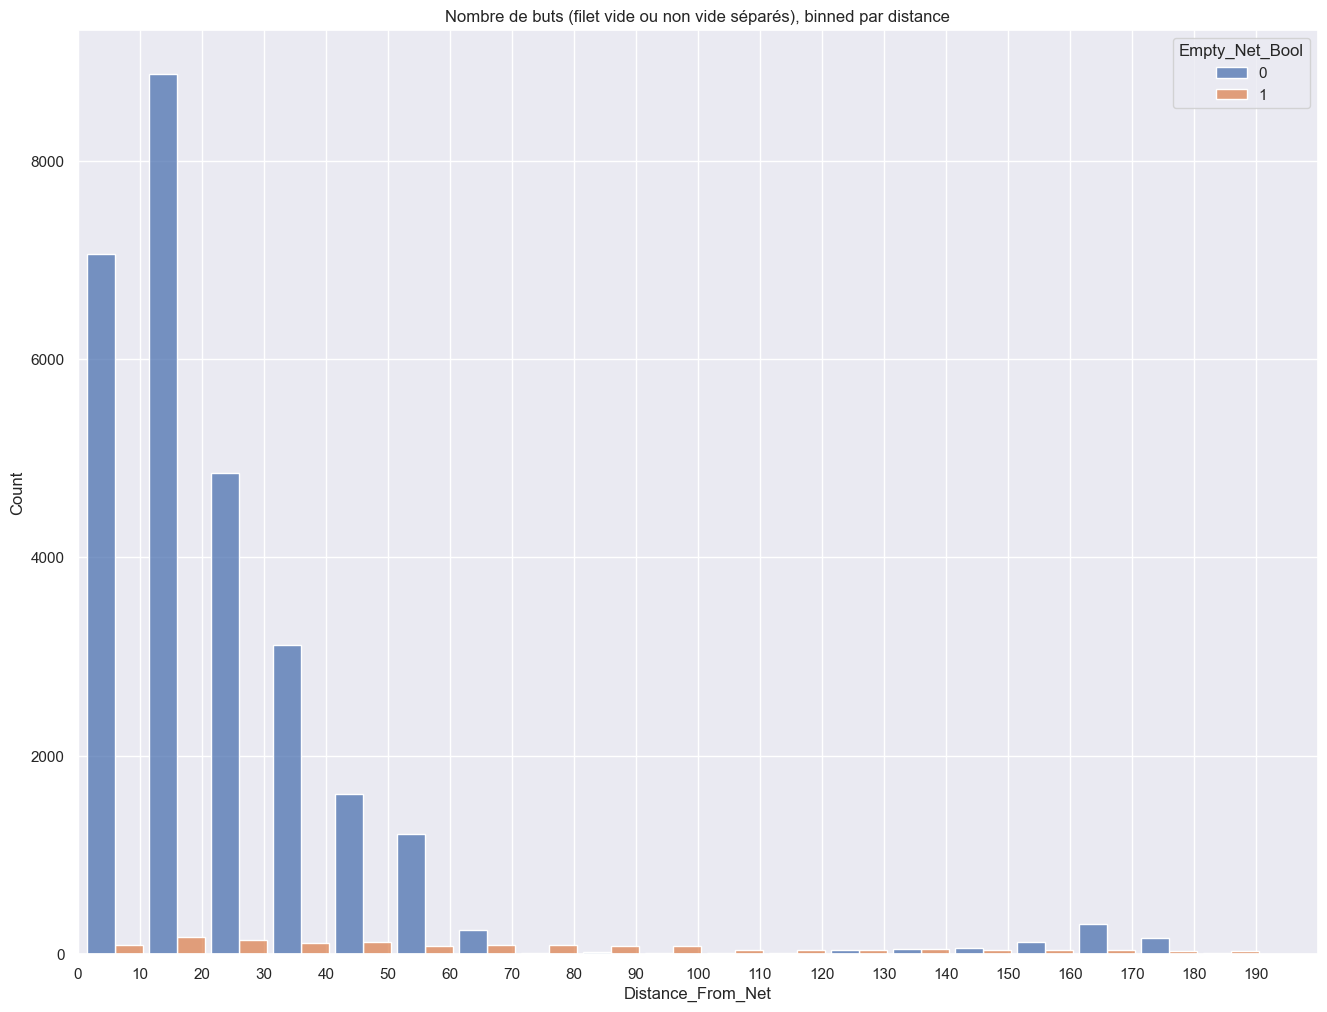

In [52]:
g = sns.histplot(df_goals, x="Distance_From_Net", hue="Empty_Net_Bool", multiple="dodge",  shrink=.9, binwidth=10)
g.set_xlim(0, 200)
g.set_xticks(range(0, 200,10))
plt.title("Nombre de buts (filet vide ou non vide séparés), binned par distance")
plt.show(g)